In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
df=pd.read_csv('hotel_bookings_10000.csv')
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,1,2016,March,10,1,0,2,1,...,No Deposit,NaN,154.0,0,Transient,27.00,0,0,Check-Out,2016-03-03
1,City Hotel,0,176,2017,March,10,10,0,2,3,...,No Deposit,9.0,NaN,0,Transient,126.00,0,1,Check-Out,2017-03-12
2,City Hotel,1,273,2016,May,20,13,1,2,2,...,Non Refund,21.0,NaN,0,Transient,95.00,0,0,Canceled,2015-12-18
3,City Hotel,0,0,2017,March,9,1,0,0,0,...,No Deposit,9.0,NaN,0,Transient,0.00,0,2,Check-Out,2017-03-01
4,City Hotel,1,71,2016,May,19,7,1,1,2,...,No Deposit,9.0,NaN,0,Transient,116.10,0,1,Canceled,2016-05-07
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,City Hotel,0,81,2017,May,19,13,2,2,2,...,No Deposit,9.0,NaN,0,Transient,121.50,0,0,Check-Out,2017-05-17
9996,Resort Hotel,0,0,2017,February,5,2,0,1,2,...,No Deposit,250.0,NaN,0,Transient,48.00,0,1,Check-Out,2017-02-03
9997,City Hotel,1,181,2016,May,19,5,2,4,2,...,Non Refund,26.0,NaN,42,Transient,90.00,0,0,Canceled,2015-12-18
9998,City Hotel,1,327,2015,September,37,9,0,2,2,...,Non Refund,1.0,NaN,0,Transient-Party,62.00,0,0,Canceled,2015-07-02


In [4]:
df.shape

(10000, 32)

In [5]:
df = df.drop(columns=[
    'company',
    'reservation_status',
    'reservation_status_date',                  
    'arrival_date_week_number',            
    'arrival_date_day_of_month',            
    'babies',                               
    'assigned_room_type',
    'agent'
])

In [6]:
df

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,meal,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,0,1,2016,March,0,2,1,0.0,BB,...,0,2,A,0,No Deposit,0,Transient,27.00,0,0
1,City Hotel,0,176,2017,March,0,2,3,0.0,BB,...,0,0,D,0,No Deposit,0,Transient,126.00,0,1
2,City Hotel,1,273,2016,May,1,2,2,0.0,BB,...,0,0,A,0,Non Refund,0,Transient,95.00,0,0
3,City Hotel,0,0,2017,March,0,0,0,0.0,BB,...,0,0,A,0,No Deposit,0,Transient,0.00,0,2
4,City Hotel,1,71,2016,May,1,1,2,0.0,SC,...,0,0,A,0,No Deposit,0,Transient,116.10,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,City Hotel,0,81,2017,May,2,2,2,0.0,SC,...,0,0,A,0,No Deposit,0,Transient,121.50,0,0
9996,Resort Hotel,0,0,2017,February,0,1,2,0.0,BB,...,0,0,A,0,No Deposit,0,Transient,48.00,0,1
9997,City Hotel,1,181,2016,May,2,4,2,0.0,BB,...,1,0,A,0,Non Refund,42,Transient,90.00,0,0
9998,City Hotel,1,327,2015,September,0,2,2,0.0,BB,...,1,0,A,0,Non Refund,0,Transient-Party,62.00,0,0


In [7]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'stays_in_weekend_nights', 'stays_in_week_nights',
       'adults', 'children', 'meal', 'country', 'market_segment',
       'distribution_channel', 'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'booking_changes', 'deposit_type', 'days_in_waiting_list',
       'customer_type', 'adr', 'required_car_parking_spaces',
       'total_of_special_requests'],
      dtype='str')

In [8]:
df.shape

(10000, 24)

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 24 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   hotel                           10000 non-null  str    
 1   is_canceled                     10000 non-null  int64  
 2   lead_time                       10000 non-null  int64  
 3   arrival_date_year               10000 non-null  int64  
 4   arrival_date_month              10000 non-null  str    
 5   stays_in_weekend_nights         10000 non-null  int64  
 6   stays_in_week_nights            10000 non-null  int64  
 7   adults                          10000 non-null  int64  
 8   children                        10000 non-null  float64
 9   meal                            10000 non-null  str    
 10  country                         9950 non-null   str    
 11  market_segment                  10000 non-null  str    
 12  distribution_channel            10000 non-nu

In [10]:
df.describe(include='object')

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,deposit_type,customer_type
count,10000,10000,10000,9950,10000,10000,10000,10000,10000
unique,2,12,5,109,7,4,8,3,4
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,No Deposit,Transient
freq,6612,1147,7718,4069,4648,8176,7261,8696,7521


In [11]:
df.isnull().sum()

hotel                              0
is_canceled                        0
lead_time                          0
arrival_date_year                  0
arrival_date_month                 0
stays_in_weekend_nights            0
stays_in_week_nights               0
adults                             0
children                           0
meal                               0
country                           50
market_segment                     0
distribution_channel               0
is_repeated_guest                  0
previous_cancellations             0
previous_bookings_not_canceled     0
reserved_room_type                 0
booking_changes                    0
deposit_type                       0
days_in_waiting_list               0
customer_type                      0
adr                                0
required_car_parking_spaces        0
total_of_special_requests          0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(1281)

In [13]:
df[df.duplicated()].head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,meal,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
111,City Hotel,0,32,2015,November,0,2,1,0.0,BB,...,0,0,A,0,No Deposit,0,Transient-Party,73.0,0,0
168,City Hotel,1,262,2015,November,1,2,2,0.0,BB,...,1,0,A,0,Non Refund,0,Transient,62.8,0,0
407,City Hotel,0,95,2016,April,0,2,2,0.0,HB,...,0,0,A,0,No Deposit,0,Transient-Party,98.0,0,0
444,City Hotel,1,364,2015,October,0,2,2,0.0,HB,...,1,0,A,0,Non Refund,0,Transient-Party,101.5,0,0
474,City Hotel,1,166,2016,November,0,3,1,0.0,BB,...,0,0,A,0,Non Refund,0,Transient,110.0,0,0


In [14]:
df_clean = df.copy()

In [15]:
df_clean = df_clean.drop_duplicates()

In [16]:
df_clean.shape

(8719, 24)

In [17]:
df_clean.duplicated().sum()

np.int64(0)

In [18]:
df_clean['is_canceled'].value_counts()

is_canceled
0    5910
1    2809
Name: count, dtype: int64

In [19]:
df_clean['is_canceled'].value_counts(normalize=True) * 100

is_canceled
0    67.783003
1    32.216997
Name: proportion, dtype: float64

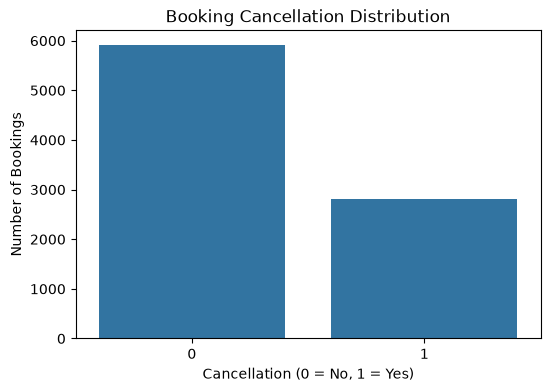

In [20]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df_clean, x='is_canceled')

plt.title('Booking Cancellation Distribution')
plt.xlabel('Cancellation (0 = No, 1 = Yes)')
plt.ylabel('Number of Bookings')

plt.show()

In [21]:
df_clean['hotel'].value_counts()

hotel
City Hotel      5515
Resort Hotel    3204
Name: count, dtype: int64

In [22]:
pd.crosstab(df_clean['hotel'], df_clean['is_canceled'])

is_canceled,0,1
hotel,,
City Hotel,3538,1977
Resort Hotel,2372,832


In [23]:
hotel_cancel = pd.crosstab(
    df_clean['hotel'],
    df_clean['is_canceled'],
    normalize='index'
) * 100

hotel_cancel

is_canceled,0,1
hotel,,
City Hotel,64.152312,35.847688
Resort Hotel,74.032459,25.967541


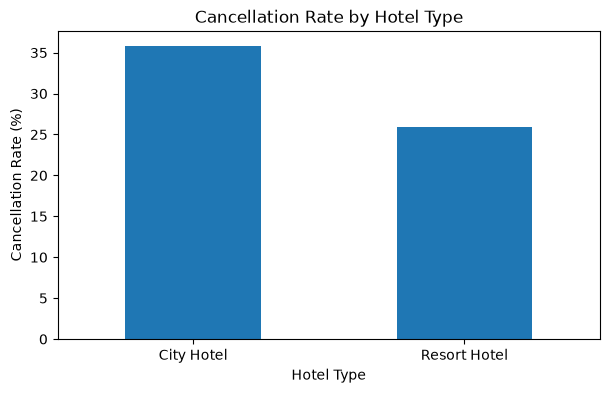

In [24]:
hotel_cancel[1].plot(kind='bar', figsize=(7, 4))
plt.title('Cancellation Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.xticks(rotation=0)
plt.show()

In [25]:
df_clean.groupby('is_canceled')['lead_time'].mean()

is_canceled
0     75.715059
1    129.105376
Name: lead_time, dtype: float64

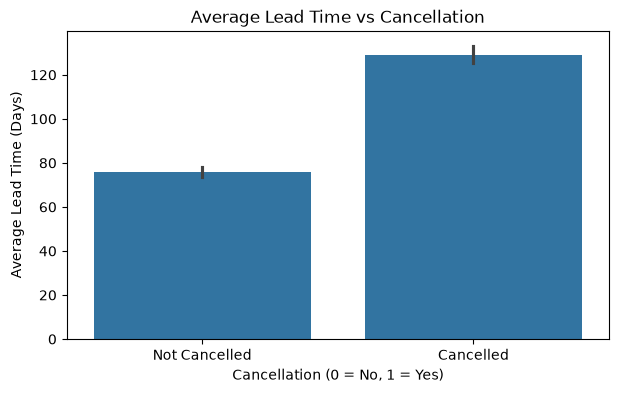

In [26]:
plt.figure(figsize=(7, 4))

sns.barplot(data=df_clean, x='is_canceled', y='lead_time')

plt.title('Average Lead Time vs Cancellation')
plt.xlabel('Cancellation (0 = No, 1 = Yes)')
plt.ylabel('Average Lead Time (Days)')
plt.xticks([0, 1], ['Not Cancelled', 'Cancelled'])

plt.show()

In [27]:
pd.crosstab(df_clean['deposit_type'], df_clean['is_canceled'])

is_canceled,0,1
deposit_type,,
No Deposit,5893,2289
Non Refund,6,518
Refundable,11,2


In [28]:
customer_cancel = pd.crosstab(
    df_clean['customer_type'],
    df_clean['is_canceled'],
    normalize='index'
) * 100

customer_cancel

is_canceled,0,1
customer_type,,
Contract,76.234568,23.765432
Group,86.046512,13.953488
Transient,64.763314,35.236686
Transient-Party,78.391960,21.608040


## Handling Missing Values

### Before handling missing values

In [29]:
df_clean.isnull().sum()

hotel                              0
is_canceled                        0
lead_time                          0
arrival_date_year                  0
arrival_date_month                 0
stays_in_weekend_nights            0
stays_in_week_nights               0
adults                             0
children                           0
meal                               0
country                           48
market_segment                     0
distribution_channel               0
is_repeated_guest                  0
previous_cancellations             0
previous_bookings_not_canceled     0
reserved_room_type                 0
booking_changes                    0
deposit_type                       0
days_in_waiting_list               0
customer_type                      0
adr                                0
required_car_parking_spaces        0
total_of_special_requests          0
dtype: int64

In [30]:
print(df_clean['country'].dtype)


str


In [31]:
df_clean['country'] = df_clean['country'].fillna('Unknown')

### After handled missing value

In [32]:
df_clean.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
booking_changes                   0
deposit_type                      0
days_in_waiting_list              0
customer_type                     0
adr                               0
required_car_parking_spaces       0
total_of_special_requests         0
dtype: int64

##  Outliers Analysis

In [33]:
numerical_cols = [
    'lead_time',
    'stays_in_weekend_nights',
    'stays_in_week_nights',
    'adults',
    'children',
    'previous_cancellations',
    'previous_bookings_not_canceled',
    'booking_changes',
    'days_in_waiting_list',
    'adr',
    'required_car_parking_spaces',
    'total_of_special_requests'
]

In [34]:
for col in numerical_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    print(f"\nColumn: {col}")
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)


Column: lead_time
Lower bound: -177.0
Upper bound: 335.0

Column: stays_in_weekend_nights
Lower bound: -3.0
Upper bound: 5.0

Column: stays_in_week_nights
Lower bound: -2.0
Upper bound: 6.0

Column: adults
Lower bound: 2.0
Upper bound: 2.0

Column: children
Lower bound: 0.0
Upper bound: 0.0

Column: previous_cancellations
Lower bound: 0.0
Upper bound: 0.0

Column: previous_bookings_not_canceled
Lower bound: 0.0
Upper bound: 0.0

Column: booking_changes
Lower bound: 0.0
Upper bound: 0.0

Column: days_in_waiting_list
Lower bound: 0.0
Upper bound: 0.0

Column: adr
Lower bound: -18.5
Upper bound: 217.5

Column: required_car_parking_spaces
Lower bound: 0.0
Upper bound: 0.0

Column: total_of_special_requests
Lower bound: -1.5
Upper bound: 2.5


In [35]:
for col in numerical_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print(col, ":", len(outliers))

lead_time : 247
stays_in_weekend_nights : 19
stays_in_week_nights : 266
adults : 2119
children : 732
previous_cancellations : 309
previous_bookings_not_canceled : 286
booking_changes : 1424
days_in_waiting_list : 180
adr : 252
required_car_parking_spaces : 578
total_of_special_requests : 248


In [36]:
df_clean['adults'].value_counts().sort_index()

adults
0       35
1     1595
2     6600
3      482
4        5
5        1
55       1
Name: count, dtype: int64

In [37]:
df_clean[df_clean['adults'] == 55]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,meal,...,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
7858,Resort Hotel,1,338,2015,October,2,0,55,0.0,HB,...,0,0,A,0,No Deposit,0,Group,0.0,0,0


In [38]:
print(df_clean['lead_time'].describe())

print(df_clean['lead_time'].sort_values(ascending=False).head(15))

count    8719.000000
mean       92.915816
std        98.910520
min         0.000000
25%        15.000000
50%        59.000000
75%       143.000000
max       629.000000
Name: lead_time, dtype: float64
5216    629
7695    626
9804    622
2142    615
1058    615
3735    601
5053    594
1518    594
932     587
889     580
2531    573
3339    566
3716    552
1553    545
5295    542
Name: lead_time, dtype: int64


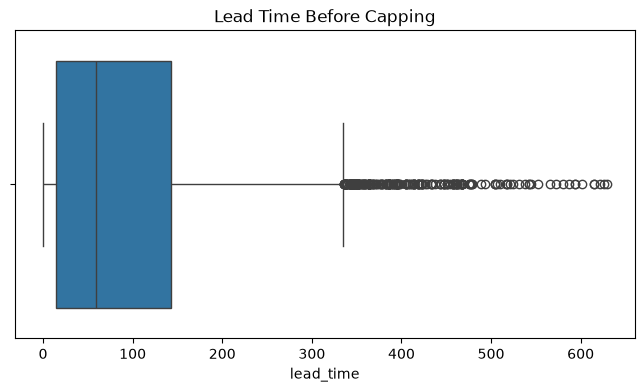

In [39]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean['lead_time'])
plt.title('Lead Time Before Capping')
plt.show()

In [40]:
Q1 = df_clean['lead_time'].quantile(0.25)
Q3 = df_clean['lead_time'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_clean['lead_time'] = df_clean['lead_time'].clip(
    lower=lower_bound,
    upper=upper_bound
)

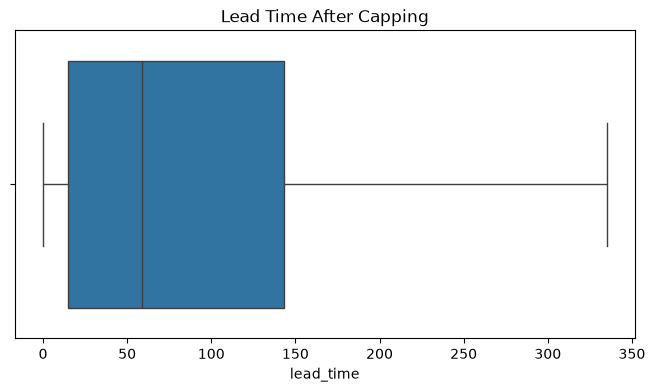

In [41]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean['lead_time'])
plt.title('Lead Time After Capping')
plt.show()

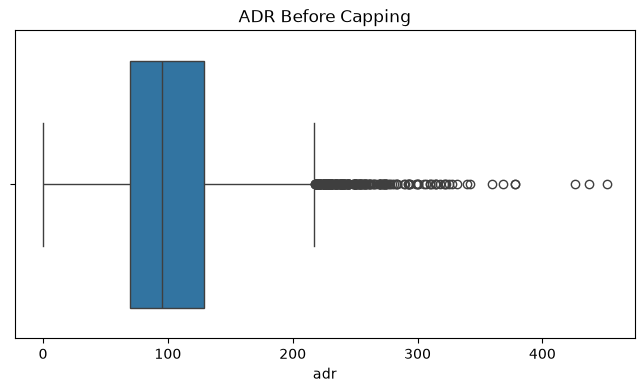

In [42]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean['adr'])
plt.title('ADR Before Capping')
plt.show()

In [43]:
df_clean[df_clean['adr'] > 217.5]['adr'].sort_values(ascending=False)

4786    451.50
2517    437.00
6501    426.25
1720    378.00
7672    378.00
         ...  
8156    218.72
8539    218.67
1417    218.00
2535    218.00
8875    217.71
Name: adr, Length: 252, dtype: float64

In [44]:
outliers = df_clean[df_clean['adr'] > 217.5]

print("Number of outliers:", len(outliers))
print("Maximum ADR:", df_clean['adr'].max())

Number of outliers: 252
Maximum ADR: 451.5


In [45]:
df_clean['adr'].sort_values().head(10)

8853    0.0
3463    0.0
6024    0.0
7557    0.0
3972    0.0
3955    0.0
6144    0.0
5589    0.0
353     0.0
9364    0.0
Name: adr, dtype: float64

In [46]:
df_clean['adr'] = df_clean['adr'].clip(upper=217.5)

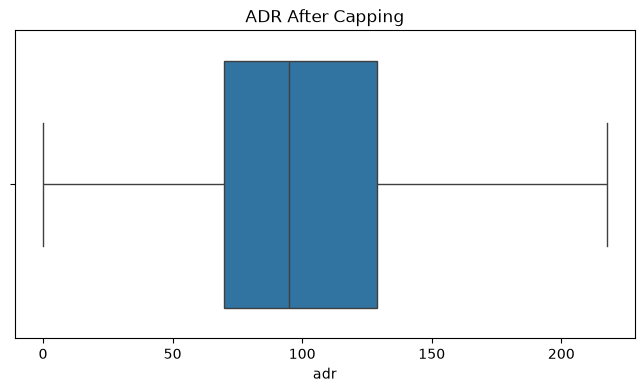

In [47]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df_clean['adr'])
plt.title('ADR After Capping')
plt.show()

## Splitting the data

In [48]:
X = df_clean.drop('is_canceled', axis=1)
y = df_clean['is_canceled']

In [49]:
y

0       0
1       0
2       1
3       0
4       1
       ..
9994    0
9995    0
9996    0
9997    1
9999    1
Name: is_canceled, Length: 8719, dtype: int64

## Train the nodel

In [50]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [51]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (6975, 23)
X_test: (1744, 23)
y_train: (6975,)
y_test: (1744,)


## Converting Categorical to Numerical

In [52]:
categorical_cols = X_train.select_dtypes(include='object').columns.tolist()
print(categorical_cols)

['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'customer_type']


In [53]:
from sklearn.preprocessing import OrdinalEncoder
encoder = OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1)

In [54]:
X_train[categorical_cols] = encoder.fit_transform(X_train[categorical_cols].astype(str))

In [55]:
X_test[categorical_cols] = encoder.transform(X_test[categorical_cols].astype(str))

In [56]:
print(X_train.head())
print(X_test.head())

      hotel  lead_time  arrival_date_year  arrival_date_month  \
33      0.0        152               2017                 6.0   
6691    0.0        110               2016                10.0   
94      1.0         87               2016                 3.0   
344     1.0         32               2016                10.0   
1122    1.0        138               2016                10.0   

      stays_in_weekend_nights  stays_in_week_nights  adults  children  meal  \
33                          0                     5       2       0.0   0.0   
6691                        1                     0       1       0.0   0.0   
94                          1                     5       2       0.0   2.0   
344                         1                     5       2       0.0   2.0   
1122                        0                     4       2       0.0   0.0   

      country  ...  previous_cancellations  previous_bookings_not_canceled  \
33       36.0  ...                       0              

In [57]:
print(X_train.isnull().sum().sum())
print(X_test.isnull().sum().sum())

0
0


## Class Imbalance

In [58]:
from imblearn.over_sampling import SMOTENC

categorical_indices = [
    X_train.columns.get_loc(col) for col in categorical_cols
]

smote = SMOTENC(
    categorical_features=categorical_indices,
    random_state=42
)

X_train_balanced, y_train_balanced = smote.fit_resample(
    X_train, y_train
)

In [59]:
print("Before balancing:")
print(y_train.value_counts())

print("\nAfter balancing:")
print(y_train_balanced.value_counts())

Before balancing:
is_canceled
0    4728
1    2247
Name: count, dtype: int64

After balancing:
is_canceled
0    4728
1    4728
Name: count, dtype: int64


## model training

In [60]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

dt_model.fit(X_train_balanced, y_train_balanced)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [61]:
y_pred = dt_model.predict(X_test)

In [62]:
print(y_pred[:10])

[0 0 1 0 0 1 0 1 1 1]


In [63]:
from sklearn.metrics import accuracy_score

dt_acc = accuracy_score(y_test, y_pred)

print("Decision Tree Accuracy:", dt_acc)

Decision Tree Accuracy: 0.7402522935779816


In [64]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.78      0.80      1182
           1       0.59      0.65      0.62       562

    accuracy                           0.74      1744
   macro avg       0.71      0.72      0.71      1744
weighted avg       0.75      0.74      0.74      1744



In [65]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[923 259]
 [194 368]]


In [66]:
from sklearn.ensemble import RandomForestClassifier
rf_balanced_model = RandomForestClassifier(n_estimators=100,random_state=42)
rf_balanced_model.fit(X_train_balanced, y_train_balanced)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [67]:
rf_pred = rf_balanced_model.predict(X_test)

In [68]:
print(rf_pred[:10])

[0 1 1 0 0 1 0 0 1 0]


In [69]:
from sklearn.metrics import accuracy_score

rf_acc = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_acc)

Random Forest Accuracy: 0.8170871559633027


In [70]:
print(classification_report(y_test, rf_pred))

              precision    recall  f1-score   support

           0       0.86      0.87      0.87      1182
           1       0.72      0.70      0.71       562

    accuracy                           0.82      1744
   macro avg       0.79      0.79      0.79      1744
weighted avg       0.82      0.82      0.82      1744



In [71]:
rf_cm = confusion_matrix(y_test, rf_pred)

print(rf_cm)

[[1029  153]
 [ 166  396]]


In [72]:
import pandas as pd

importance = rf_balanced_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                           Feature  Importance
9                          country    0.151194
1                        lead_time    0.150179
20                             adr    0.115018
22       total_of_special_requests    0.086841
10                  market_segment    0.081101
3               arrival_date_month    0.054618
5             stays_in_week_nights    0.044887
19                   customer_type    0.037955
17                    deposit_type    0.031417
11            distribution_channel    0.030944
21     required_car_parking_spaces    0.028112
4          stays_in_weekend_nights    0.027862
2                arrival_date_year    0.026943
16                 booking_changes    0.026702
15              reserved_room_type    0.021860
6                           adults    0.017074
8                             meal    0.016685
0                            hotel    0.016160
7                         children    0.014049
13          previous_cancellations    0.010171
14  previous_

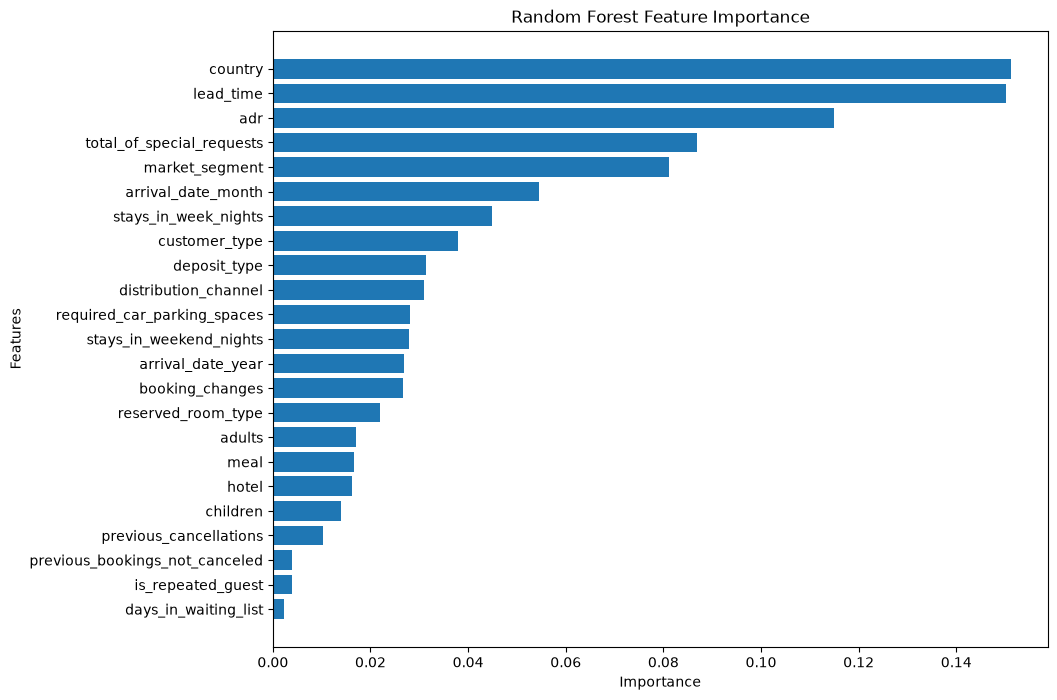

In [74]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))
plt.barh(feature_importance['Feature'],feature_importance['Importance'])
plt.xlabel('Importance')
plt.ylabel('Features')
plt.title('Random Forest Feature Importance')
plt.gca().invert_yaxis()
plt.show()

## Saving the model

In [75]:
import joblib
joblib.dump(rf_balanced_model, 'hotel_cancellation_model.pkl')
joblib.dump(encoder, 'hotel_encoder.pkl')
joblib.dump(X_train.columns.tolist(), 'feature_columns.pkl')
joblib.dump(categorical_cols, 'categorical_cols.pkl')
print("Model and preprocessing files saved successfully!")

Model and preprocessing files saved successfully!


In [76]:
import os

files = [
    'hotel_cancellation_model.pkl',
    'hotel_encoder.pkl',
    'feature_columns.pkl',
    'categorical_cols.pkl'
]

for file in files:
    print(file, ":", "Found" if os.path.exists(file) else "Not found")

hotel_cancellation_model.pkl : Found
hotel_encoder.pkl : Found
feature_columns.pkl : Found
categorical_cols.pkl : Found
